In [1]:
import os, random, hashlib
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from imutils import paths
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

path = "../data/raw"
IMG_SIZE = (224, 224)
SEED = 42

I0000 00:00:1792494159.207879   27161 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792494159.208427   27161 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792494159.840283   27161 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792494161.931581   27161 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

### Load the cleaned dataset (deduplicated, shuffled, resized to 224x224)

In [2]:
image_paths = list(paths.list_images(path))

# find duplicates with the hash, skip broken imgs
hashes = {}
for p in image_paths:
    if cv2.imread(p) is None:
        continue
    with open(p, "rb") as f:
        h = hashlib.md5(f.read()).hexdigest()
    hashes.setdefault(h, []).append(p)

# keep 1st file of each group, drop the group if classes are mixed
files = []
for g in hashes.values():
    if len({p.split(os.path.sep)[-2] for p in g}) == 1:
        files.append(g[0])

random.seed(SEED)
random.shuffle(files)

# read + resize + label
X, labels, file_list = [], [], []
for p in files:
    img = cv2.imread(p)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)
    X.append(img)
    labels.append(p.split(os.path.sep)[-2])
    file_list.append(p)

# class names -> numbers
CLASSES = sorted(set(labels))
X = np.array(X)
y = np.array([CLASSES.index(l) for l in labels])
print(X.shape, X.dtype, y.shape)  # nb imgs, size, channels

(6726, 224, 224, 3) uint8 (6726,)


### Split into train / validation / test (70/15/15, stratified, before any augmentation)

In [3]:

X_train, X_temp, y_train, y_temp, p_train, p_temp = train_test_split(
    X, y, file_list, test_size=0.30, stratify=y, random_state=SEED
)

X_val, X_test, y_val, y_test, p_val, p_test = train_test_split(
    X_temp, y_temp, p_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print(X_train.shape, X_val.shape, X_test.shape)

# MobileNetV2 preprocessing
X_train = tf.keras.applications.mobilenet_v2.preprocess_input(
    X_train.astype("float32")
)
X_val = tf.keras.applications.mobilenet_v2.preprocess_input(
    X_val.astype("float32")
)
X_test = tf.keras.applications.mobilenet_v2.preprocess_input(
    X_test.astype("float32")
)



(4708, 224, 224, 3) (1009, 224, 224, 3) (1009, 224, 224, 3)


### Verify the split: no overlap between sets, class proportions preserved

In [4]:
print(len(set(p_train) & set(p_val)), len(set(p_train) & set(p_test)), len(set(p_val) & set(p_test)))  # overlaps, should be 0 0 0

for name, lab in [("train", y_train), ("val", y_val), ("test", y_test)]:
    values, counts = np.unique(lab, return_counts=True)
    print(name, np.round(counts / len(lab), 3))  # class proportions, should be close

0 0 0
train [0.241 0.243 0.257 0.259]
val [0.241 0.243 0.258 0.259]
test [0.241 0.244 0.257 0.259]


### Build the tf.data datasets (cache, shuffle on train, batch, prefetch)

In [5]:
def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b))  # normalize
    ds = ds.cache()
    if training:
        ds = ds.shuffle(1000, seed=SEED)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, training=True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test, y_test)

xb, yb = next(iter(train_ds))
print(xb.shape, xb.dtype, yb.shape)  # one batch, should be (32,224,224,3)

E0000 00:00:1792494207.892583   27161 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


(32, 224, 224, 3) <dtype: 'float32'> (32,)


W0000 00:00:1792494230.776303   27161 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


### Normalization to [-1, 1]: before and after

float32 -1.0 1.0
float32 -1.0078431 -0.99215686


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0078431..-0.99215686].


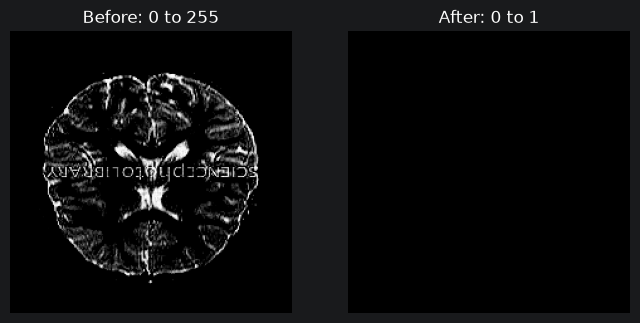

In [6]:

img = X_train[0].astype("float32")
norm = tf.keras.applications.mobilenet_v2.preprocess_input(img.copy())

print(img.dtype, img.min(), img.max())  # Before
print(norm.dtype, norm.min(), norm.max())  # Approximately -1 to 1

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img)
axes[0].set_title("Before: 0 to 255")
axes[0].axis("off")
axes[1].imshow(norm)
axes[1].set_title("After: -1 to 1")
axes[1].axis("off")
plt.show()

### Data augmentation suited to MRI (training set only)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0078431..-0.99215686].


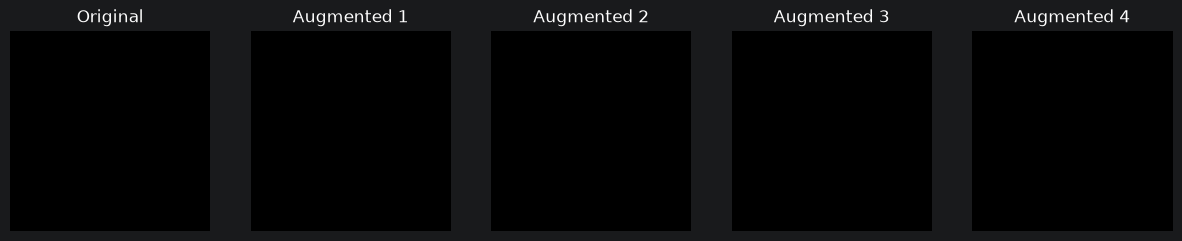

In [7]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
])

sample = tf.convert_to_tensor(norm[None, ...])
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(norm)
axes[0].set_title("Original")
axes[0].axis("off")
for i in range(1, 5):
    augmented = augmentation(sample, training=True)[0].numpy().clip(0, 1)
    axes[i].imshow(augmented)
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")
plt.show()

### Class weights computed on the training set only

In [8]:
weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
class_weight = dict(enumerate(weights))
print(class_weight)  # bigger weight = rarer class

{0: np.float64(1.0379188712522045), 1: np.float64(1.0288461538461537), 2: np.float64(0.9711221122112211), 3: np.float64(0.9663382594417077)}


### Save the processed data

In [9]:
for cls in CLASSES:
    os.makedirs(f"../data/processed/{cls}", exist_ok=True)

for i in range(len(X)):
    img = cv2.cvtColor(X[i], cv2.COLOR_RGB2BGR)  # cv2 wants bgr
    cv2.imwrite(f"../data/processed/{labels[i]}/{i}.png", img)

print(len(X), len(list(paths.list_images("../data/processed"))))  # both should match


6726 6726
